# 08 Final test

This is the one run on the test years 2022-2025. The model has been frozen in `reports/final_model.json` since notebook 02, and the rules for this run were fixed before it:

* the model is refitted with the frozen settings on the same rows as before, and it has to reproduce the validation AUC before we look at the test;
* Platt scaling is learned on non-anomalous validation rows and only applied here, so nothing is learned from the test years;
* the main number is ROC AUC on all test rows, with 95% bootstrap intervals at two levels: whole expeditions and the wider whole peak x year x season groups;
* Brier and log loss are read after calibration;
* the same metrics are repeated without the rows from expeditions that did not attempt the climb (`TERMREASON` 12);
* to see whether the model ages, we compare the test years with 2018 and 2019, because 2020 and spring 2021 were anomalous seasons.

We report what comes out. No feature, setting or calibration changes after this run.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score

from src import models as M
from src.config import EXPERIMENT_LOG_PATH, PROCESSED_DIR, TABLES_DIR
from src.error_analysis import group_report, reliability_table, residual_icc, within_group_auc
from src.evaluate import add_age_bins, evaluate, fmt, paired_difference, plot_calibration
from src.features import to_number
from src.leakage_audit import with_post_climb_fields
from src.split import fit_frame, load_features, time_split
from src.style import BLUE, GRID, INK, MUTED, ORANGE, apply_style, save_figure

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 70)
apply_style()
N_BOOT = 1000

final = M.load_final_config()
exped = pd.read_parquet(PROCESSED_DIR / "exped.parquet")
members = pd.read_parquet(PROCESSED_DIR / "members.parquet")
peaks = pd.read_parquet(PROCESSED_DIR / "peaks.parquet")
train, val, test = time_split(load_features())
train_fit = fit_frame(train)
test = with_post_climb_fields(test, exped, members)
clean_val = ~val["ANOMALOUS_SEASON"].to_numpy(dtype=bool)
PEAK_NAMES = {**peaks.set_index("PEAKID")["PKNAME"].to_dict(), "OTHER": "Other peaks"}
assert len(test) == 9114
print(f"train {len(train):,} (fit {len(train_fit):,}) | val {len(val):,} (clean {clean_val.sum():,}) | test {len(test):,}, expeditions {test['EXPID'].nunique():,}")
print(f"anomalous rows in test: {int(test['ANOMALOUS_SEASON'].astype(bool).sum())}")

train 37,969 (fit 37,448) | val 5,042 (clean 4,236) | test 9,114, expeditions 1,027
anomalous rows in test: 0


## 1. The frozen model on validation
Before opening the test we refit the model and check that it still gives the validation AUC from notebook 02. If it does not, the notebook stops here and we find out why.

In [2]:
model = M.refit_lightgbm(train_fit, final["iterations"], params=final["params"], features=final["features"], seeds=tuple(final["seeds"]))
y_val = M.target(val)
p_val_raw = model.predict(val)
log = pd.read_csv(EXPERIMENT_LOG_PATH)
logged_auc = log.loc[(log["model"] == "LightGBM tuned (5 seeds)") & (log["view"] == "val_all"), "roc_auc"].item()
val_auc = roc_auc_score(y_val, p_val_raw)
print(f"validation AUC {val_auc:.4f}, logged {logged_auc:.4f}")
assert abs(val_auc - logged_auc) < 0.001, "the refitted model is not the frozen one"
calibrator = M.Calibrator("platt").fit(p_val_raw[clean_val], y_val[clean_val])
p_val = M.crossfit_calibrate(val, p_val_raw, "platt", fit_rows=clean_val)

validation AUC 0.7116, logged 0.7116


## 2. Test metrics
Platt scaling keeps the order of the predictions, so it leaves the test AUC as it is and changes only Brier and log loss. The validation rows are calibrated out of fold, as in notebook 05, and are here for comparison.

In [3]:
def level_keys(df):
    return {"expedition": df["EXPID"].astype(str).to_numpy(),
            "peak x year x season": (df["PEAK_GROUP"].astype(str) + "|" + df["YEAR"].astype(str) + "|" + df["SEASON"].astype(str)).to_numpy()}

y = M.target(test)
p_raw = model.predict(test)
p = calibrator.predict(p_raw)
levels = level_keys(test)
print(f"test: actual share of summits {y.mean():.3f}, predicted before calibration {p_raw.mean():.3f}, after {p.mean():.3f}")
print(f"validation: actual share of summits {y_val.mean():.3f}, predicted before calibration {p_val_raw.mean():.3f}, after {p_val.mean():.3f}")

rows = []
for split, probabilities, truth, q, keys in (("test", "before calibration", y, p_raw, levels),
                                             ("test", "after Platt", y, p, levels),
                                             ("validation", "after Platt, out of fold", y_val, p_val, level_keys(val))):
    for level, groups in keys.items():
        rows.append({"split": split, "probabilities": probabilities, "resampled by": level, "groups": len(np.unique(groups)), **fmt(evaluate(truth, q, groups, n_boot=N_BOOT))})
metrics = pd.DataFrame(rows).set_index(["split", "probabilities", "resampled by"])
metrics.to_csv(TABLES_DIR / "08_test_metrics.csv")
display(metrics)

test: actual share of summits 0.527, predicted before calibration 0.515, after 0.578
validation: actual share of summits 0.537, predicted before calibration 0.496, after 0.556


groups               roc_auc                 brier              log_loss
split      probabilities            resampled by                                                                                  
test       before calibration       expedition              1027  0.692 [0.673, 0.709]  0.221 [0.217, 0.226]  0.634 [0.623, 0.644]
                                    peak x year x season     120  0.692 [0.657, 0.731]  0.221 [0.211, 0.232]  0.634 [0.611, 0.656]
           after Platt              expedition              1027  0.692 [0.673, 0.709]  0.224 [0.218, 0.231]  0.640 [0.626, 0.655]
                                    peak x year x season     120  0.692 [0.657, 0.731]  0.224 [0.207, 0.242]  0.640 [0.602, 0.680]
validation after Platt, out of fold expedition               922  0.712 [0.684, 0.739]  0.216 [0.206, 0.225]  0.620 [0.597, 0.642]
                                    peak x year x season      95  0.712 [0.653, 0.760]  0.216 [0.194, 0.237]  0.620 [0.571, 0.668]

## 3. Without expeditions that did not attempt the climb
These rows stayed in the data because `TERMREASON` is known only after the climb. Nobody in them can reach the summit, and on validation they raised AUC from 0.7095 to 0.7116.

In [4]:
no_attempt = (to_number(test["TERMREASON"]) == 12).to_numpy()
print(f"rows with TERMREASON 12: {int(no_attempt.sum())} of {len(test):,}, from {test.loc[no_attempt, 'EXPID'].nunique()} expeditions, summits {int(y[no_attempt].sum())}")
without = pd.DataFrame({level: {"rows": int((~no_attempt).sum()), **fmt(evaluate(y[~no_attempt], p[~no_attempt], groups[~no_attempt], n_boot=N_BOOT))} for level, groups in levels.items()}).T
without.to_csv(TABLES_DIR / "08_without_no_attempt.csv")
display(without)

rows with TERMREASON 12: 26 of 9,114, from 7 expeditions, summits 0


,rows,roc_auc,brier,log_loss
expedition,9088,"0.691 [0.672, 0.709]","0.224 [0.218, 0.230]","0.640 [0.626, 0.655]"
peak x year x season,9088,"0.691 [0.655, 0.727]","0.224 [0.208, 0.242]","0.640 [0.604, 0.681]"


## 4. Against the baselines
Every model was fitted on the same training rows. The comparison uses predictions before calibration and both levels of resampling, as in notebook 05.

In [5]:
cv_catboost = M.cv_catboost(train_fit, params=M.DEFAULT_CATBOOST)
preds = {"LightGBM final": p_raw,
         "Constant (train mean)": M.constant_baseline(train_fit, test),
         "Rule: peak x season rate": M.PeakSeasonRate().fit(train_fit).predict(test),
         "Logistic regression": M.fit_logreg(train_fit).predict(test),
         "CatBoost typical": M.refit_catboost(train_fit, int(cv_catboost["iterations"].mean()), params=M.DEFAULT_CATBOOST).predict(test)}
models = pd.DataFrame({name: {"mean_p": round(float(q.mean()), 3), **fmt(evaluate(y, q, levels["expedition"], n_boot=N_BOOT))} for name, q in preds.items()}).T
models.to_csv(TABLES_DIR / "08_models.csv")
display(models)

rows = []
for name in ("Logistic regression", "Rule: peak x season rate", "CatBoost typical"):
    for level, groups in levels.items():
        rows.append({"LightGBM minus": name, "resampled by": level, **fmt(paired_difference(y, p_raw, preds[name], groups, n_boot=N_BOOT), digits=4)})
paired = pd.DataFrame(rows).set_index(["LightGBM minus", "resampled by"])
paired.to_csv(TABLES_DIR / "08_paired.csv")
display(paired)

,mean_p,roc_auc,brier,log_loss
LightGBM final,0.515,"0.692 [0.673, 0.709]","0.221 [0.217, 0.226]","0.634 [0.623, 0.644]"
Constant (train mean),0.387,"0.500 [0.500, 0.500]","0.269 [0.264, 0.274]","0.732 [0.721, 0.742]"
Rule: peak x season rate,0.425,"0.606 [0.584, 0.626]","0.250 [0.245, 0.256]","0.695 [0.683, 0.708]"
Logistic regression,0.617,"0.685 [0.667, 0.703]","0.239 [0.229, 0.247]","0.698 [0.673, 0.721]"
CatBoost typical,0.484,"0.673 [0.651, 0.694]","0.229 [0.225, 0.234]","0.650 [0.640, 0.660]"


roc_auc                       brier                    log_loss
LightGBM minus           resampled by                                                                                          
Logistic regression      expedition            0.0075 [-0.0042, 0.0186]  -0.0173 [-0.0231, -0.0113]  -0.0644 [-0.0813, -0.0469]
                         peak x year x season  0.0075 [-0.0133, 0.0266]  -0.0173 [-0.0318, -0.0021]  -0.0644 [-0.1099, -0.0162]
Rule: peak x season rate expedition             0.0861 [0.0628, 0.1108]  -0.0289 [-0.0354, -0.0223]  -0.0616 [-0.0758, -0.0480]
                         peak x year x season   0.0861 [0.0308, 0.1446]  -0.0289 [-0.0511, -0.0086]  -0.0616 [-0.1071, -0.0195]
CatBoost typical         expedition             0.0189 [0.0083, 0.0300]  -0.0077 [-0.0106, -0.0048]  -0.0164 [-0.0226, -0.0100]
                         peak x year x season  0.0189 [-0.0037, 0.0426]  -0.0077 [-0.0126, -0.0023]  -0.0164 [-0.0268, -0.0049]

## 5. Calibration

,n,mean_p,mean_y
bin,,,
1,912,0.212,0.214
2,911,0.363,0.317
3,911,0.459,0.398
4,912,0.529,0.490
5,911,0.587,0.533
6,911,0.637,0.571
7,912,0.685,0.602
8,911,0.724,0.661
9,911,0.767,0.723


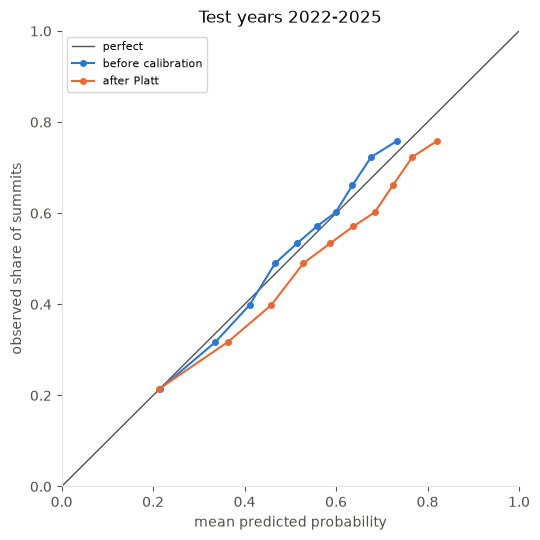

In [6]:
reliability = reliability_table(y, p)
reliability.round(3).to_csv(TABLES_DIR / "08_reliability.csv")
display(reliability.round(3))

fig, ax = plt.subplots(figsize=(5.5, 5.5))
plot_calibration(y, {"before calibration": p_raw, "after Platt": p}, ax=ax, title="Test years 2022-2025")
plt.tight_layout()
save_figure(fig, "08_calibration.png")
plt.show()

## 6. Year by year
The model was fitted up to 2017 and stays the same for all eight years. The numbers for 2018-2021 come from notebook 05.

,n,expeditions,mean_y,mean_p,gap,roc_auc,auc_low,auc_high,brier,log_loss
YEAR,,,,,,,,,,
2018,1708,344,0.578,0.552,-0.026,0.737,0.694,0.775,0.203,0.591
2019,1833,358,0.597,0.571,-0.027,0.740,0.700,0.778,0.199,0.583
2020,136,21,0.699,0.456,-0.242,0.612,0.454,0.768,0.276,0.757
2021,1365,199,0.387,0.550,0.163,0.675,0.621,0.727,0.247,0.691
2022,2186,272,0.438,0.560,0.122,0.679,0.634,0.720,0.238,0.670
2023,2203,265,0.549,0.571,0.023,0.691,0.656,0.728,0.221,0.635
2024,2196,236,0.559,0.582,0.023,0.703,0.673,0.732,0.218,0.627
2025,2529,254,0.557,0.597,0.040,0.694,0.659,0.728,0.219,0.630


,2018-2019,2022-2025
resampled by,,
expedition,"0.739 [0.707, 0.767]","0.692 [0.673, 0.709]"
peak x year x season,"0.739 [0.685, 0.781]","0.692 [0.657, 0.731]"


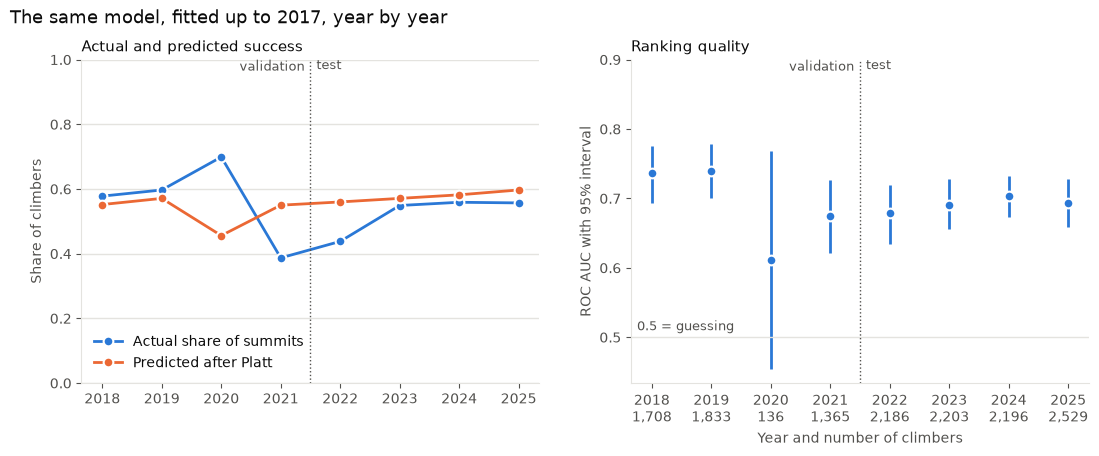

In [7]:
test_years = group_report(test, p, "YEAR", n_boot=N_BOOT)
val_years = pd.read_csv(TABLES_DIR / "05_by_year.csv", index_col="YEAR").drop(columns="mean_p_raw")
val_years.index = val_years.index.astype(str)
by_year = pd.concat([val_years, test_years.round(3)]).rename_axis("YEAR")
by_year.to_csv(TABLES_DIR / "08_by_year.csv")
display(by_year)

before = val["YEAR"].isin([2018, 2019]).to_numpy(dtype=bool)
ageing = pd.DataFrame({"2018-2019": {level: fmt(evaluate(y_val[before], p_val_raw[before], groups[before], n_boot=N_BOOT))["roc_auc"] for level, groups in level_keys(val).items()},
                       "2022-2025": {level: metrics.loc[("test", "before calibration", level), "roc_auc"] for level in levels}}).rename_axis("resampled by")
ageing.to_csv(TABLES_DIR / "08_ageing.csv")
display(ageing)

years = by_year.index.astype(int).to_numpy()
fig, (left, right) = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"wspace": 0.2})
left.plot(years, by_year["mean_y"], color=BLUE, lw=2, marker="o", ms=7, mec="white", mew=1.5, label="Actual share of summits")
left.plot(years, by_year["mean_p"], color=ORANGE, lw=2, marker="o", ms=7, mec="white", mew=1.5, label="Predicted after Platt")
left.set_ylim(0, 1)
left.set_xticks(years)
left.set_ylabel("Share of climbers")
left.legend(frameon=False, loc="lower left", labelcolor=INK)
left.grid(axis="y", color=GRID, lw=1)
left.set_axisbelow(True)
left.set_title("Actual and predicted success", loc="left", fontsize=11)
right.errorbar(years, by_year["roc_auc"], yerr=[by_year["roc_auc"] - by_year["auc_low"], by_year["auc_high"] - by_year["roc_auc"]], fmt="o", ms=7, color=BLUE, mec="white", mew=1.5, capsize=0, lw=2)
right.axhline(0.5, color=GRID, lw=1)
right.text(years[0] - 0.25, 0.51, "0.5 = guessing", color=MUTED, fontsize=9)
right.set_xticks(years, [f"{year}\n{int(n):,}" for year, n in zip(years, by_year["n"])])
right.set_xlabel("Year and number of climbers")
right.set_xlim(years[0] - 0.35, years[-1] + 0.35)
right.set_ylim(min(0.45, by_year["auc_low"].min() - 0.02), 0.9)
right.set_ylabel("ROC AUC with 95% interval")
right.set_title("Ranking quality", loc="left", fontsize=11)
for ax in (left, right):
    ax.axvline(2021.5, color=MUTED, lw=1, ls=":")
    top = ax.get_ylim()[1]
    ax.text(2021.4, top, "validation", ha="right", va="top", color=MUTED, fontsize=9)
    ax.text(2021.6, top, "test", ha="left", va="top", color=MUTED, fontsize=9)
fig.suptitle("The same model, fitted up to 2017, year by year", x=0.07, y=1.0, ha="left", fontsize=13, color=INK)
save_figure(fig, "08_by_year.png")
plt.show()

Agencies and routes that did not appear up to 2017 reach the model as missing values. This table shows how many rows that affects each year.

In [8]:
seen = M.fit_categories(train_fit, final["features"])
later = pd.concat([val[["YEAR", "AGENCY", "ROUTE1"]], test[["YEAR", "AGENCY", "ROUTE1"]]], ignore_index=True)
new_levels = pd.DataFrame({column: (~M._cat(later[column]).isin(seen[column])).groupby(later["YEAR"].astype(str)).mean() for column in ("AGENCY", "ROUTE1")})
new_levels.round(3).to_csv(TABLES_DIR / "08_new_levels.csv")
display(new_levels.round(3))

,AGENCY,ROUTE1
YEAR,,
2018,0.243,0.013
2019,0.253,0.017
2020,0.051,0.022
2021,0.256,0.032
2022,0.318,0.021
2023,0.352,0.009
2024,0.351,0.014
2025,0.348,0.005


## 7. Peaks, season, age, sex and experience

In [9]:
by_peak = group_report(test, p, "PEAK_GROUP")
by_peak.insert(0, "name", [PEAK_NAMES.get(k, k) for k in by_peak.index])
by_peak = by_peak.sort_values("n", ascending=False)
by_peak.round(3).to_csv(TABLES_DIR / "08_by_peak.csv")
display(by_peak.round(3))

seasons = {"1": "Spring", "2": "Summer", "3": "Autumn", "4": "Winter"}
prior = to_number(test["PRIOR_EXPEDITIONS"])
views = test.assign(
    SEASON_NAME=test["SEASON"].astype(str).map(seasons),
    AGE_GROUP=add_age_bins(test),
    SEX_KNOWN=test["SEX"].astype("string").fillna("unknown"),
    EXPERIENCE=np.select([prior.isna(), prior == 0, prior < 5], ["unknown", "first expedition", "1-4 earlier"], "5 or more earlier"))
tables = {column: group_report(views, p, column) for column in ("SEASON_NAME", "AGE_GROUP", "SEX_KNOWN", "EXPERIENCE")}
pd.concat(tables, names=["view", "group"]).round(3).to_csv(TABLES_DIR / "08_by_group.csv")
for name, table in tables.items():
    print(name)
    display(table.round(3))

,name,n,expeditions,mean_y,mean_p,gap,roc_auc,auc_low,auc_high,brier,log_loss
PEAK_GROUP,,,,,,,,,,,
AMAD,Ama Dablam,2378,200,0.520,0.617,0.097,0.615,0.587,0.643,0.249,0.695
EVER,Everest,1875,175,0.694,0.685,-0.009,0.630,0.592,0.667,0.202,0.593
MANA,Manaslu,1425,121,0.592,0.665,0.073,0.669,0.620,0.722,0.227,0.646
HIML,Himlung Himal,734,70,0.409,0.478,0.070,0.664,0.609,0.718,0.227,0.644
OTHER,Other peaks,687,197,0.342,0.421,0.078,0.650,0.587,0.723,0.221,0.635
LHOT,Lhotse,481,63,0.514,0.596,0.083,0.662,0.610,0.708,0.235,0.662
MAKA,Makalu,275,35,0.535,0.552,0.017,0.692,0.632,0.761,0.220,0.630
BARU,Baruntse,229,26,0.188,0.262,0.074,0.568,0.436,0.722,0.162,0.504
KANG,Kangchenjunga,219,24,0.566,0.555,-0.011,0.712,0.650,0.780,0.217,0.623


SEASON_NAME


,n,expeditions,mean_y,mean_p,gap,roc_auc,auc_low,auc_high,brier,log_loss
SEASON_NAME,,,,,,,,,,
Autumn,5104,558,0.515,0.566,0.051,0.686,0.658,0.712,0.226,0.646
Spring,3910,444,0.548,0.597,0.049,0.694,0.665,0.721,0.221,0.634
Winter,86,20,0.291,0.440,0.149,0.698,0.503,0.973,0.197,0.572


AGE_GROUP


,n,expeditions,mean_y,mean_p,gap,roc_auc,auc_low,auc_high,brier,log_loss
AGE_GROUP,,,,,,,,,,
25-34,1936,731,0.579,0.636,0.057,0.680,0.646,0.710,0.223,0.638
35-44,2756,831,0.596,0.643,0.047,0.657,0.632,0.685,0.225,0.643
45-54,2366,753,0.517,0.554,0.037,0.677,0.649,0.703,0.228,0.649
55+,1651,626,0.357,0.427,0.069,0.665,0.635,0.696,0.217,0.623
<25,395,260,0.554,0.628,0.074,0.671,0.604,0.735,0.228,0.651


SEX_KNOWN


,n,expeditions,mean_y,mean_p,gap,roc_auc,auc_low,auc_high,brier,log_loss
SEX_KNOWN,,,,,,,,,,
F,2020,705,0.586,0.613,0.027,0.678,0.651,0.711,0.220,0.631
M,7094,1002,0.510,0.569,0.058,0.693,0.675,0.710,0.225,0.643


EXPERIENCE


,n,expeditions,mean_y,mean_p,gap,roc_auc,auc_low,auc_high,brier,log_loss
EXPERIENCE,,,,,,,,,,
1-4 earlier,2842,824,0.542,0.588,0.047,0.706,0.679,0.734,0.218,0.627
5 or more earlier,1271,594,0.555,0.623,0.068,0.699,0.667,0.736,0.222,0.638
first expedition,4993,853,0.512,0.562,0.050,0.680,0.659,0.704,0.228,0.648


## 8. Ranking inside groups
The same view as in notebook 05: how well the model separates climbers who face the same peak, the same season or the same expedition.

In [10]:
rows = [{"level": "all rows (pooled)", "auc": roc_auc_score(y, p_raw), "groups": 1, "rows": len(y), "error_icc": np.nan}]
for name, keys in (("inside one peak", test["PEAK_GROUP"].astype(str).to_numpy()), ("inside one peak x year x season", levels["peak x year x season"]), ("inside one expedition", levels["expedition"])):
    rows.append({"level": name, **within_group_auc(y, p_raw, keys), "error_icc": residual_icc(y, p, keys)})
inside = pd.DataFrame(rows).set_index("level")
inside.round(3).to_csv(TABLES_DIR / "08_inside_groups.csv")
display(inside.round(3))

,auc,groups,rows,error_icc
level,,,,
all rows (pooled),0.692,1,9114,NaN
inside one peak,0.638,16,9084,0.016
inside one peak x year x season,0.645,80,8836,0.119
inside one expedition,0.644,588,7017,0.257
